# Replace the cross-modal map in scMultiSim

This notebook keeps the balanced COATI experiment fixed and changes only the frozen RNA-to-ATAC map. The two alternatives are **MLP + t**, which appends time to the RNA coordinates, and **Ridge**, a global linear map. Both maps were trained on the same paired RNA10 and ATAC8 cells used by the FiLM example.

COATI is trained for 3,000 iterations on CPU with $C_y=0.1$. The final comparison uses the same observed-cell UMAP and the same 15-nearest-neighbor lineage test for both maps.


In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import sys
import uuid

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from threadpoolctl import threadpool_limits

import coati as ct

%matplotlib inline
threadpool_limits(limits=1)
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

TIME_KEYS = ("time1", "time2", "time3", "time4")
TIME_VALUES = np.arange(4, dtype=float)
RAW_DATA_BASE_URL = "https://raw.githubusercontent.com/shankswang953/COATI/main/examples/data/scmultisim"
SOURCE_FILES = (
    "all_time_scRNA_pca10.npz",
    "all_time_scATAC_pca8_no_pc2.npz",
    "all_time_celltype.npz",
    "primal_norm_params_rna10_w2.pt",
    "secondary_norm_params_atac8_no_pc2_w2.pt",
    "observed_rna10_umap.npz",
)
MAP_FILES = {
    "MLP + t": "scmultisim_rna10_atac8_mlp_t_T.pt",
    "Ridge": "scmultisim_rna10_atac8_ridge_T.pt",
}
device = "cpu"
print("Training device:", device)


Training device: cpu


## Prepare the paired AnnData

RNA PCA10 is stored in `obsm["X_pca"]`, ATAC PCA8 in `obsm["X_atac"]`, and the four stages in `obs`. The UMAP coordinates are used only after training.


In [2]:
repo_root = next((root for root in (Path.cwd(), *Path.cwd().parents)
                  if (root / "notebooks/scMultisim/trained_maps.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from a cloned COATI repository.")
sys.path.insert(0, str(repo_root / "notebooks/scMultisim"))
from trained_maps import load_trained_map

repo_data_dir = repo_root / "examples/data/scmultisim"
data_dir = repo_data_dir if repo_data_dir.is_dir() else Path("outputs/scmultisim-data")
data_dir.mkdir(parents=True, exist_ok=True)


def obtain_data(filename):
    path = data_dir / filename
    if not path.is_file():
        print("Downloading", filename)
        urlretrieve(f"{RAW_DATA_BASE_URL}/{filename}", path)
    return path


paired = ct.TemporalData.from_npz(
    obtain_data(SOURCE_FILES[0]), times=TIME_VALUES, keys=TIME_KEYS,
    secondary_path=obtain_data(SOURCE_FILES[1]),
)
with np.load(obtain_data(SOURCE_FILES[2]), allow_pickle=False) as archive:
    celltypes = np.concatenate([archive[key].astype(str) for key in TIME_KEYS])

cells = paired.to_anndata(
    celltype=celltypes, use_rep="X_pca", secondary_key="X_atac", warn=False,
)
cells.obs["stage"] = pd.Categorical(
    np.repeat(TIME_KEYS, [len(x) for x in paired.primary]),
    categories=TIME_KEYS, ordered=True,
)
display(
    cells.obs["stage"].value_counts(sort=False).rename("cells").reset_index()
    .style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)


stage,cells
time1,2006
time2,2001
time3,3008
time4,2985


## Load the two frozen maps

The notebook selects each saved map by name. Model reconstruction and checkpoint loading are kept in the shared tutorial helper rather than repeated here.


In [3]:
maps = {name: load_trained_map(obtain_data(filename))
        for name, filename in MAP_FILES.items()}
with torch.no_grad():
    for name, model in maps.items():
        x = torch.tensor(paired.primary[0][:16])
        probe = model(x, torch.zeros(16)) if name == "MLP + t" else model(x)
        assert probe.shape == (16, 8) and torch.isfinite(probe).all()
        print(f"{name}: RNA10 → ATAC8 | trainable during COATI: {any(p.requires_grad for p in model.parameters())}")


MLP + t: RNA10 → ATAC8 | trainable during COATI: False
Ridge: RNA10 → ATAC8 | trainable during COATI: False


## Train COATI with each map

The vector-field architecture, data, normalization, seed-controlled training procedure, and all loss coefficients are identical. Only `T_model` changes.


In [4]:
def make_config():
    return ct.Config(
        multimodal=True,
        balanced=True,
        iterations=3000,
        batch_size=128,
        learning_rate=1e-4,
        hidden_dim=400,
        n_layers=3,
        activation="leaky_relu",
        secondary_weight=0.1,
        manifold_weight=10.0,
        energy_weight=1.0,
        matching_weight=100.0,
        median_n_sample=128,
        floor_n_sample=128,
        dt=0.1,
        blur_coeff=0.05,
        floor_buffer_std=1.0,
        density_topk=25,
        density_hinge=0.01,
        terminal_density_weight=1.0,
        sync_density_loss=True,
        sync_pdf_loss=True,
        adaptive_lambda=True,
        lambda_min_pri=5.0,
        lambda_min_sec=10.0,
        lambda_max_pri=100.0,
        lambda_max_sec=100.0,
        eta_lambda_pri=10.0,
        eta_lambda_sec=10.0,
        dual_warmup=1000,
        dual_decay=1.0,
        device=device,
        extra={
            "pdf_coefficient_pri": 100.0,
            "pdf_coefficient_sec": 100.0,
            "lambda_init": 100.0,
            "lambda_init_pri": 100.0,
            "lambda_init_sec": 100.0,
        },
    )


results = {}
run_dirs = {}
for name, model in maps.items():
    run_dir = Path("outputs") / (
        "scmultisim-balanced-cy0p1-" + name.lower().replace(" + ", "-").replace(" ", "-")
        + "-" + uuid.uuid4().hex[:8]
    )
    print(f"Training with {name} ...")
    results[name] = ct.train_vector_field(
        cells,
        config=make_config(),
        output_dir=run_dir,
        T_model=model,
        use_rep="X_pca",
        secondary_obsm_key="X_atac",
        primal_norm_path=obtain_data(SOURCE_FILES[3]),
        sec_norm_path=obtain_data(SOURCE_FILES[4]),
        verbose=False,
    )
    run_dirs[name] = run_dir
    print("Completed:", run_dir)


Training with MLP + t ...


Completed: outputs/scmultisim-balanced-cy0p1-mlp-t-342fd4a8
Training with Ridge ...


Completed: outputs/scmultisim-balanced-cy0p1-ridge-3a12eadc


In [5]:
training_quality = pd.concat(
    [pd.Series(result.evaluate(), name="value").rename_axis("metric").reset_index()
     .assign(map=name)
     for name, result in results.items()],
    ignore_index=True,
)[["map", "metric", "value"]]
display(
    training_quality.style.hide(axis="index")
    .format({"value": "{:.4f}"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)


map,metric,value
MLP + t,endpoint_sinkhorn_before,1.2191
MLP + t,endpoint_sinkhorn_after,0.0209
MLP + t,kinetic_energy_mean,1.2929
MLP + t,endpoint_sampling_floor,0.0265
MLP + t,secondary_endpoint_sinkhorn,0.0252
Ridge,endpoint_sinkhorn_before,1.2191
Ridge,endpoint_sinkhorn_after,0.0289
Ridge,kinetic_energy_mean,1.3052
Ridge,endpoint_sampling_floor,0.0265
Ridge,secondary_endpoint_sinkhorn,0.0508


## Generated snapshots in the reference UMAP

All initial cells are evolved to the four observed times. Every generated cell keeps the color of its initial lineage; lines are intentionally omitted. The left panel is the fixed UMAP of all observed cells.


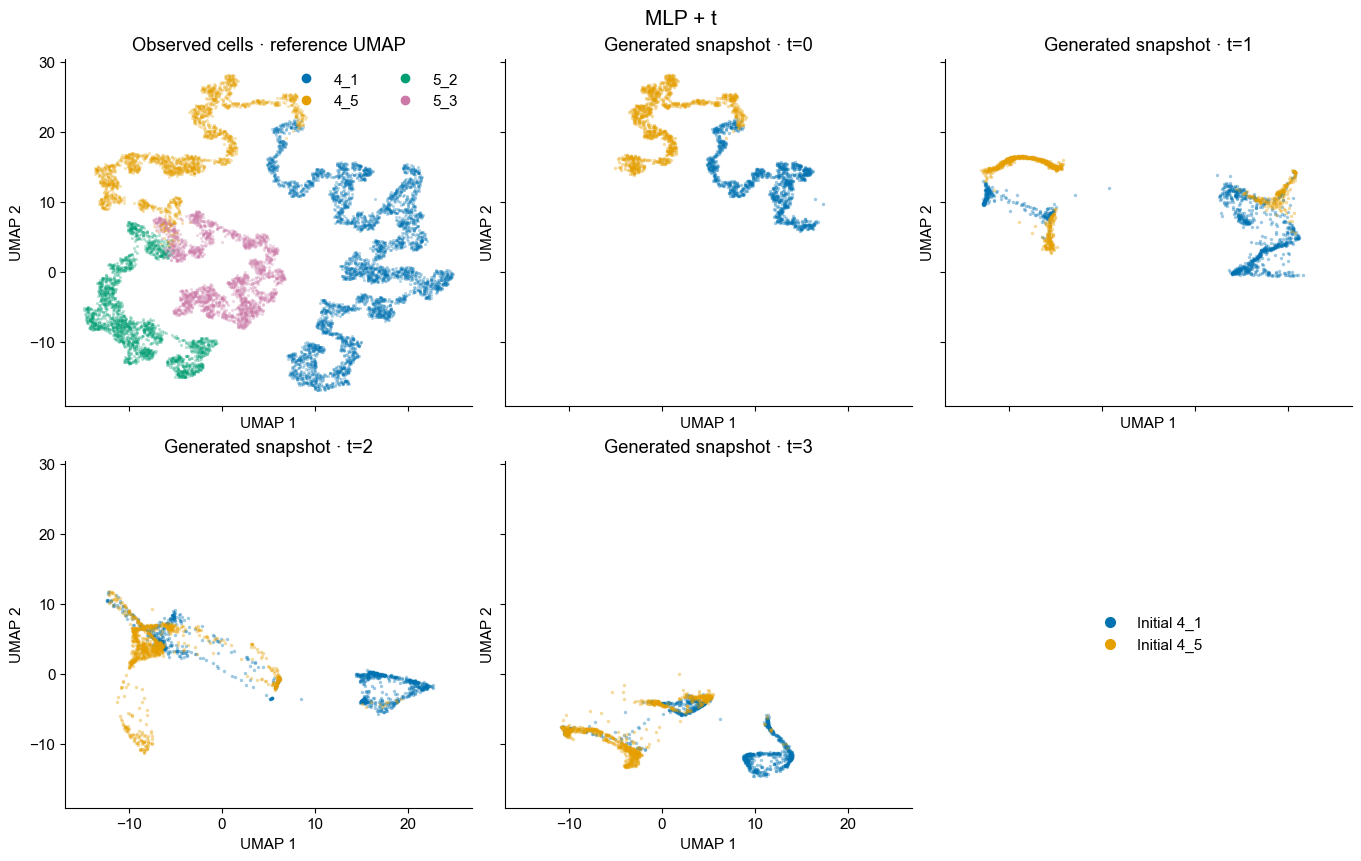

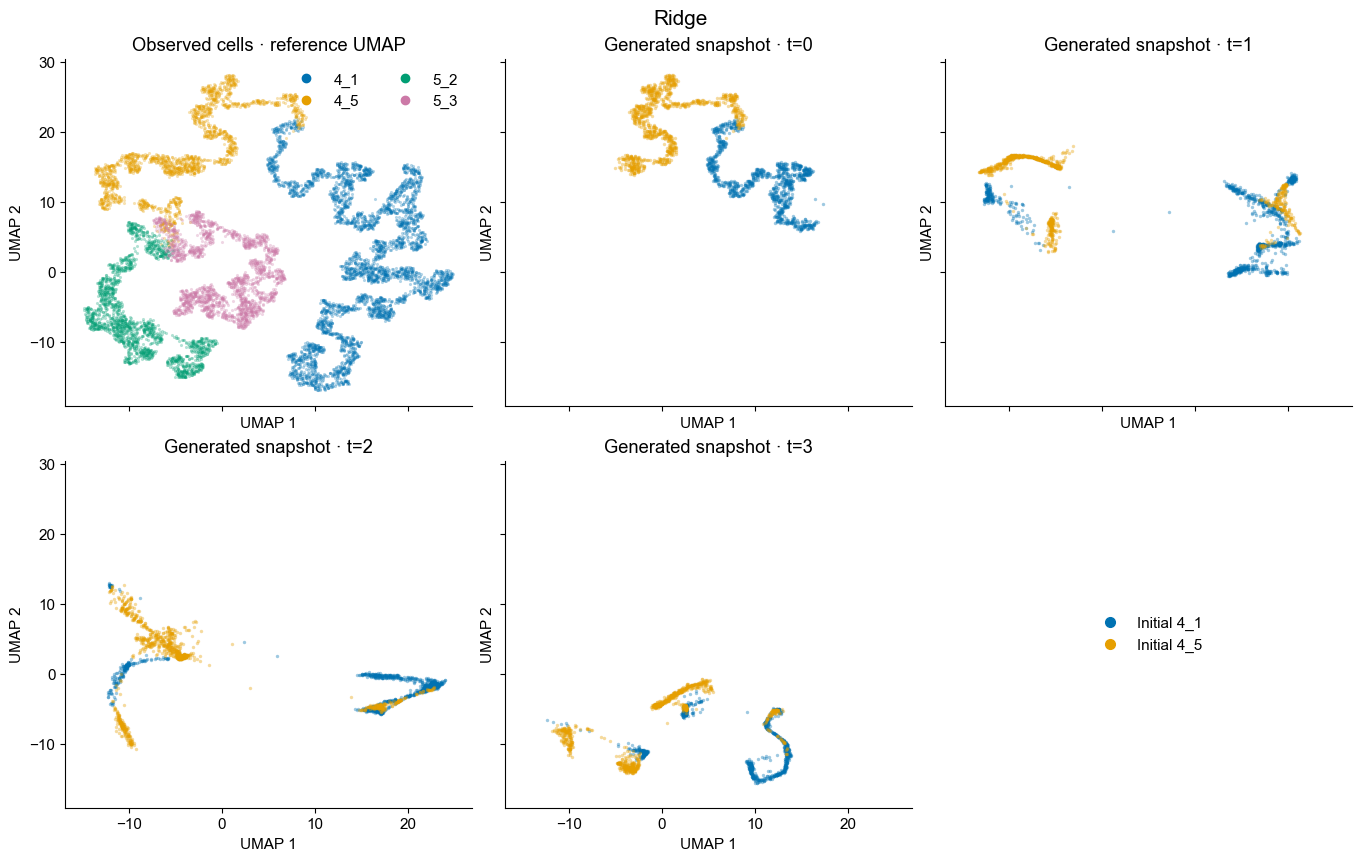

In [6]:
with np.load(obtain_data(SOURCE_FILES[5]), allow_pickle=False) as archive:
    observed_umap = archive["observed_umap"]
    observed_population = archive["observed_population"].astype(str)
np.testing.assert_array_equal(observed_population, celltypes)

reference_projector = KNeighborsRegressor(n_neighbors=25, weights="distance", n_jobs=-1)
reference_projector.fit(np.concatenate(paired.primary), observed_umap)
initial_lineages = celltypes[:len(paired.primary[0])]
palette = dict(zip(sorted(np.unique(celltypes)), ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))


def plot_generated_snapshots(name, result):
    prediction = result.predict(initial=paired.primary[0], times=TIME_VALUES, raw=True)
    projected = reference_projector.predict(prediction["primary"].reshape(-1, 10))
    snapshot_umap = projected.reshape(len(TIME_VALUES), len(paired.primary[0]), 2)

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5), sharex=True, sharey=True,
                             layout="constrained")
    reference_ax = axes[0, 0]
    snapshot_axes = (axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1])
    for label in sorted(palette):
        mask = celltypes == label
        reference_ax.scatter(*observed_umap[mask].T, s=5, alpha=.30, linewidths=0,
                             color=palette[label], rasterized=True)
    for time, points, ax in zip(TIME_VALUES, snapshot_umap, snapshot_axes):
        for label in sorted(np.unique(initial_lineages)):
            mask = initial_lineages == label
            ax.scatter(*points[mask].T, s=6, alpha=.38, linewidths=0,
                       color=palette[label], rasterized=True)
        ax.set_title(f"Generated snapshot · t={time:g}")
    observed_handles = [Line2D([], [], marker="o", linestyle="", color=palette[label],
                               label=label, markersize=6) for label in sorted(palette)]
    reference_ax.legend(handles=observed_handles, frameon=False, ncol=2)
    reference_ax.set_title("Observed cells · reference UMAP")
    initial_handles = [Line2D([], [], marker="o", linestyle="", color=palette[label],
                              label=f"Initial {label}", markersize=7)
                       for label in sorted(np.unique(initial_lineages))]
    axes[1, 2].legend(handles=initial_handles, frameon=False, loc="center")
    axes[1, 2].axis("off")
    for ax in (reference_ax, *snapshot_axes):
        ax.set(xlabel="UMAP 1", ylabel="UMAP 2")
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(name, fontsize=15)
    plt.show()


for name, result in results.items():
    plot_generated_snapshots(name, result)


## Lineage preservation

A distance-weighted 15-nearest-neighbor classifier assigns generated RNA10 states to observed branches. Terminal error uses the endpoint assignment. Global error marks a cell incorrect if it leaves its initial branch at any of 60 post-initial evaluation times.


In [7]:
snapshot_labels = np.split(
    celltypes, np.cumsum([len(snapshot) for snapshot in paired.primary])[:-1]
)
source_lineage = snapshot_labels[0]
evaluation_times = np.linspace(TIME_VALUES[0], TIME_VALUES[-1], 61)

terminal_classifier = KNeighborsClassifier(
    n_neighbors=15, weights="distance", n_jobs=-1
).fit(paired.primary[-1], snapshot_labels[-1])
observed_rna = np.concatenate(paired.primary)
observed_lineage = np.where(celltypes == "4_1", "4_1", "4_5")
global_classifier = KNeighborsClassifier(
    n_neighbors=15, weights="distance", n_jobs=-1
).fit(observed_rna, observed_lineage)


def lineage_errors(name, result):
    dense = result.predict(
        initial=paired.primary[0], times=evaluation_times, raw=True
    )["primary"]
    terminal_population = terminal_classifier.predict(dense[-1]).astype(str)
    terminal_lineage = np.where(terminal_population == "4_1", "4_1", "4_5")
    terminal_error = terminal_lineage != source_lineage
    assigned = global_classifier.predict(
        dense.reshape(-1, dense.shape[-1])
    ).reshape(len(evaluation_times), len(source_lineage))
    global_error = (assigned[1:] != source_lineage[None, :]).any(axis=0)
    return pd.DataFrame({
        "map": name,
        "metric": ["Terminal lineage error", "Global lineage error"],
        "errors": [terminal_error.sum(), global_error.sum()],
        "cells": len(source_lineage),
        "rate": [terminal_error.mean(), global_error.mean()],
    })


lineage_metrics = pd.concat(
    [lineage_errors(name, result) for name, result in results.items()],
    ignore_index=True,
)
display(
    lineage_metrics.style.hide(axis="index")
    .format({"rate": "{:.2%}"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)


map,metric,errors,cells,rate
MLP + t,Terminal lineage error,378,2006,18.84%
MLP + t,Global lineage error,553,2006,27.57%
Ridge,Terminal lineage error,490,2006,24.43%
Ridge,Global lineage error,592,2006,29.51%


In [8]:
for name, path in run_dirs.items():
    print(f"{name}: {path}")


MLP + t: outputs/scmultisim-balanced-cy0p1-mlp-t-342fd4a8
Ridge: outputs/scmultisim-balanced-cy0p1-ridge-3a12eadc
